In [9]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow joblib

Defaulting to user installation because normal site-packages is not writeable


In [10]:
# ============================================================
# 0. IMPORT LIBRARY & KONFIGURASI
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

# Sesuaikan path ini jika file berada di folder lain.
# Path berikut sesuai dengan file yang diunggah pada percakapan ini.
FILES = {
    2011: r"C:\Users\Pongo\Downloads\gas+turbine+co+and+nox+emission+data+set\gt_2011.csv",
    2012: r"C:\Users\Pongo\Downloads\gas+turbine+co+and+nox+emission+data+set\gt_2012.csv",
    2013: r"C:\Users\Pongo\Downloads\gas+turbine+co+and+nox+emission+data+set\gt_2013.csv",
    2014: r"C:\Users\Pongo\Downloads\gas+turbine+co+and+nox+emission+data+set\gt_2014.csv",
    2015: r"C:\Users\Pongo\Downloads\gas+turbine+co+and+nox+emission+data+set\gt_2015.csv",
}

FEATURES = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
TARGETS = ["NOX", "CO"]
EXPECTED_COLUMNS = FEATURES + TARGETS

In [11]:
# ============================================================
# 1. LOAD, VALIDASI, DAN GABUNGKAN 5 FILE
# ============================================================
frames = []
file_audit = []

for year, path in FILES.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File {path} tidak ditemukan. Periksa kembali FILES di bagian konfigurasi."
        )

    temp = pd.read_csv(path)
    temp.columns = temp.columns.str.strip()

    missing_columns = set(EXPECTED_COLUMNS) - set(temp.columns)
    extra_columns = set(temp.columns) - set(EXPECTED_COLUMNS)
    if missing_columns:
        raise ValueError(f"Kolom hilang pada file {path}: {missing_columns}")
    if extra_columns:
        print(f"PERINGATAN: kolom tambahan pada {path}: {extra_columns}")

    temp = temp[EXPECTED_COLUMNS].copy()
    temp["Year"] = year

    file_audit.append({
        "Year": year,
        "Rows": len(temp),
        "Columns": len(EXPECTED_COLUMNS),
        "Missing_values": int(temp[EXPECTED_COLUMNS].isna().sum().sum()),
        "Duplicate_rows_within_file": int(temp[EXPECTED_COLUMNS].duplicated().sum())
    })
    frames.append(temp)

df = pd.concat(frames, ignore_index=True)
df["Year"] = df["Year"].astype(int)

audit_df = pd.DataFrame(file_audit)
print("AUDIT PER FILE")
display(audit_df)
print("\nUkuran dataset gabungan:", df.shape)
print("\nContoh data:")
display(df.head())
print("\nInformasi data:")
df.info()

# Duplikat diperiksa tetapi tidak langsung dihapus.
# Nilai sensor yang sama dapat terjadi secara alami pada pengukuran operasional.
print("\nDuplikat seluruh kolom (termasuk Year):", df.duplicated().sum())
print("Duplikat fitur + target (tanpa Year):",
      df[EXPECTED_COLUMNS].duplicated().sum())

AUDIT PER FILE


,Year,Rows,Columns,Missing_values,Duplicate_rows_within_file
0,2011,7411,11,0,0
1,2012,7628,11,0,0
2,2013,7152,11,0,0
3,2014,7158,11,0,7
4,2015,7384,11,0,0



Ukuran dataset gabungan: (36733, 12)

Contoh data:


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,NOX,CO,Year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,81.952,0.32663,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,82.377,0.44784,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,83.776,0.45144,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,82.505,0.23107,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,82.028,0.26747,2011



Informasi data:
<class 'pandas.DataFrame'>
RangeIndex: 36733 entries, 0 to 36732
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      36733 non-null  float64
 1   AP      36733 non-null  float64
 2   AH      36733 non-null  float64
 3   AFDP    36733 non-null  float64
 4   GTEP    36733 non-null  float64
 5   TIT     36733 non-null  float64
 6   TAT     36733 non-null  float64
 7   TEY     36733 non-null  float64
 8   CDP     36733 non-null  float64
 9   NOX     36733 non-null  float64
 10  CO      36733 non-null  float64
 11  Year    36733 non-null  int64  
dtypes: float64(11), int64(1)
memory usage: 3.4 MB

Duplikat seluruh kolom (termasuk Year): 7
Duplikat fitur + target (tanpa Year): 7


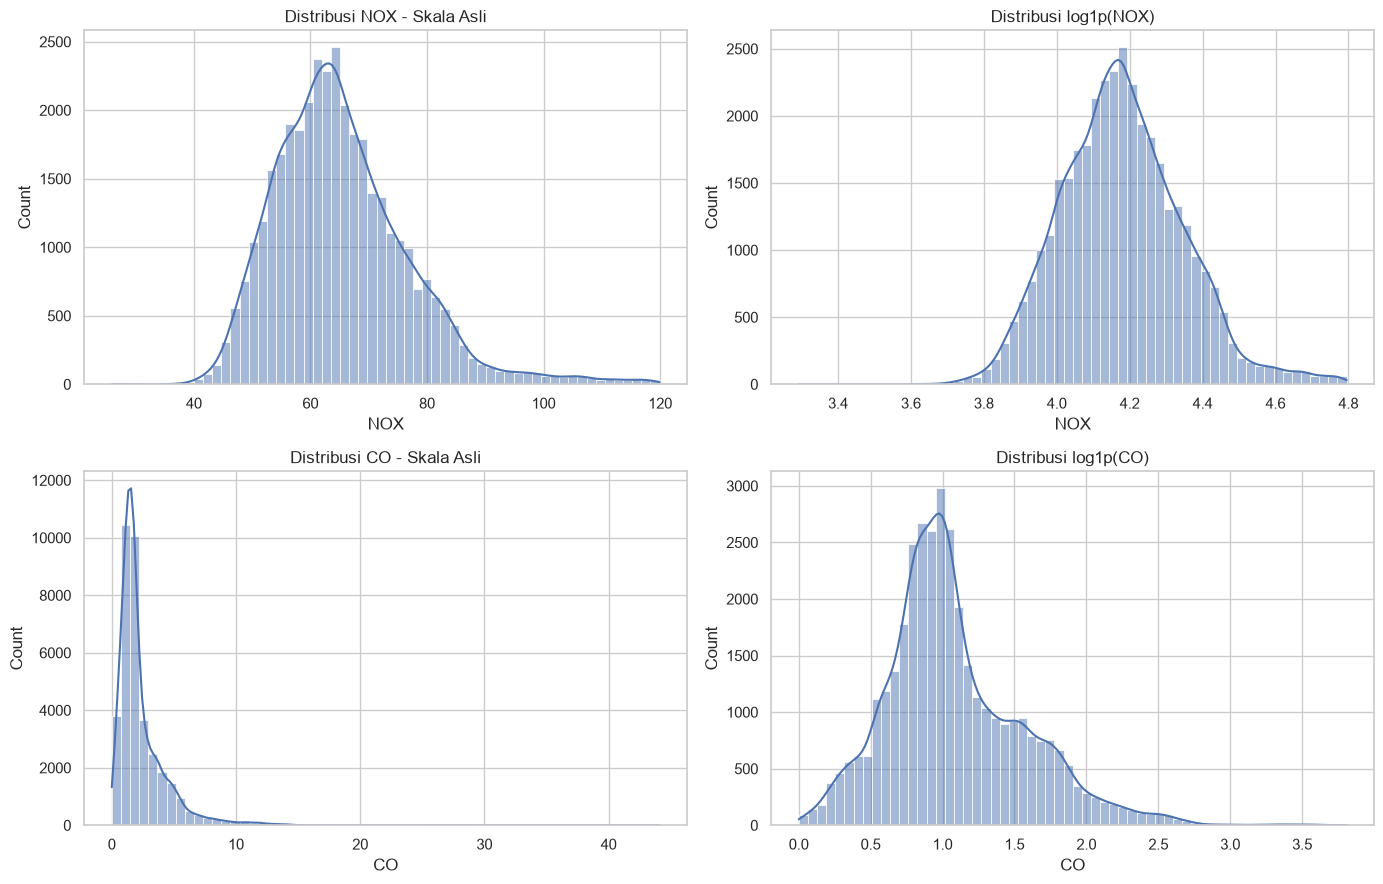


RINGKASAN DISTRIBUSI TARGET


,mean,median,std,min,max,skew
NOX,65.293067,63.8490,11.678357,25.905000,119.910,1.026779
CO,2.372468,1.7135,2.262672,0.000388,44.103,4.838174


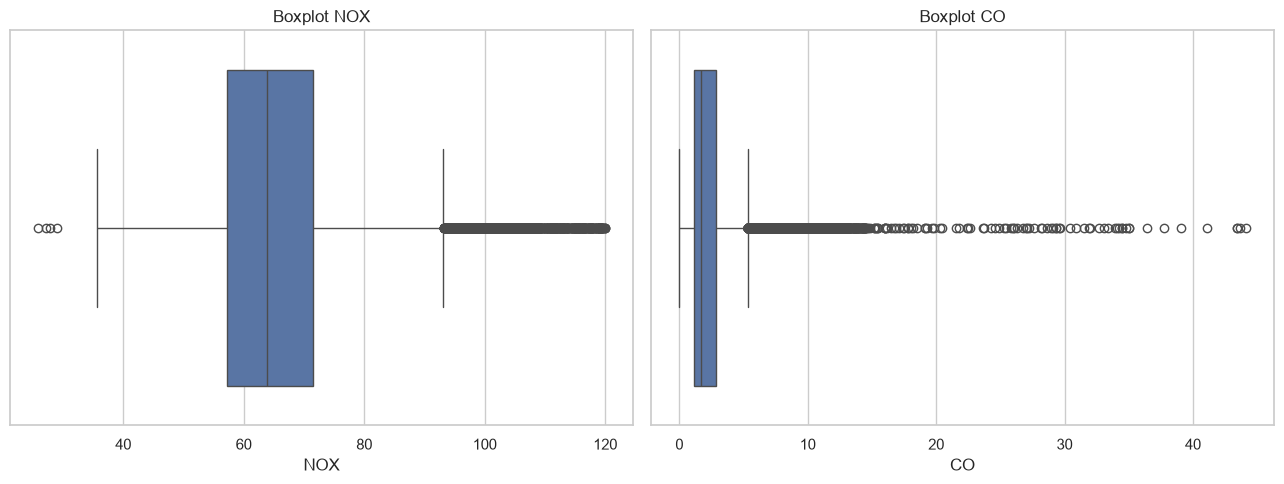


DETEKSI OUTLIER DENGAN IQR (bukan keputusan penghapusan)


,Variable,Lower_IQR,Upper_IQR,Outlier_count,Outlier_percent
6,TAT,536.74000,558.02000,4955,13.489233
10,CO,-1.30835,5.33365,2655,7.227833
9,NOX,35.58300,93.12700,936,2.548117
1,AP,996.50000,1029.30000,612,1.666077
3,AFDP,1.82365,5.90885,557,1.516348
5,TIT,1034.00000,1134.80000,315,0.857540
2,AH,36.40600,121.15800,132,0.359350
7,TEY,95.00500,173.52500,33,0.089837
8,CDP,9.30500,14.98500,10,0.027223
4,GTEP,14.23100,37.95900,7,0.019056


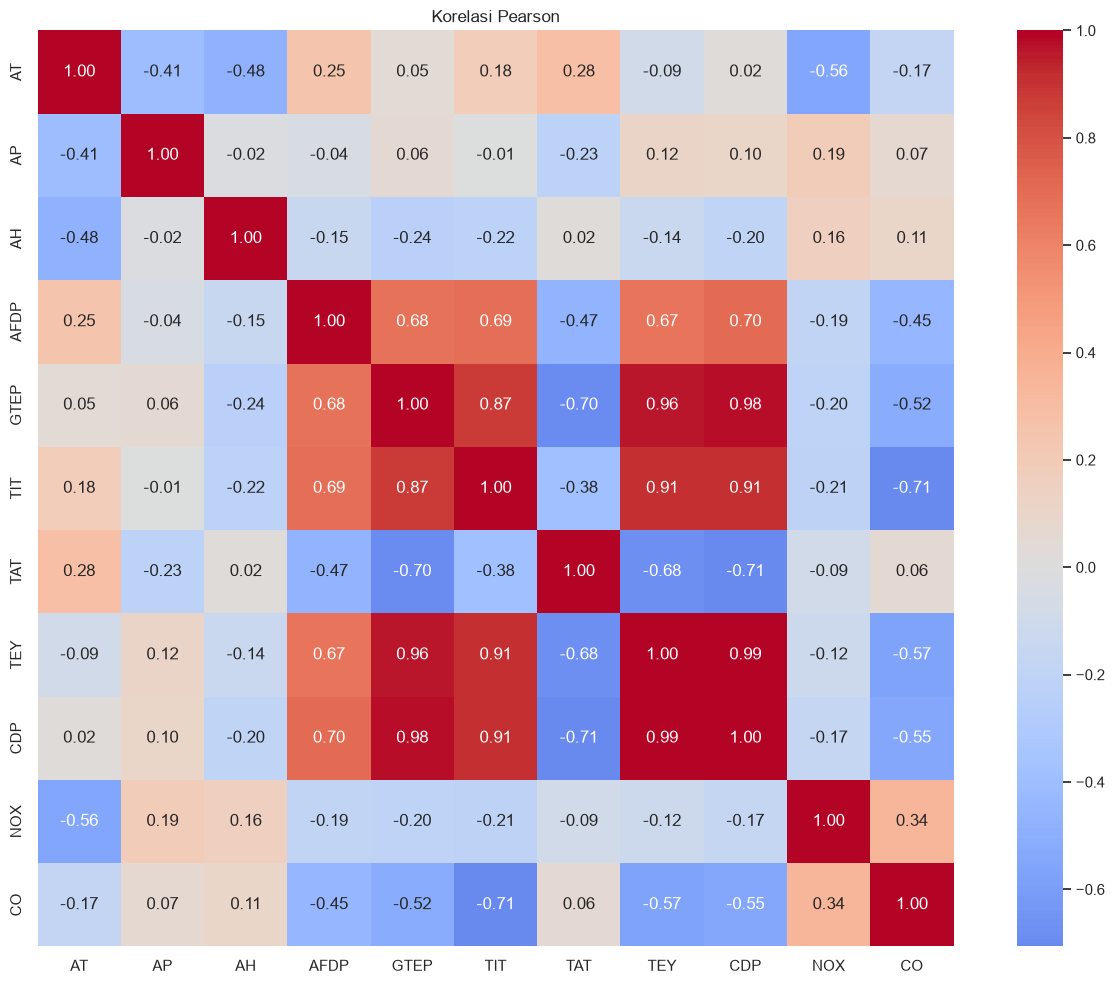

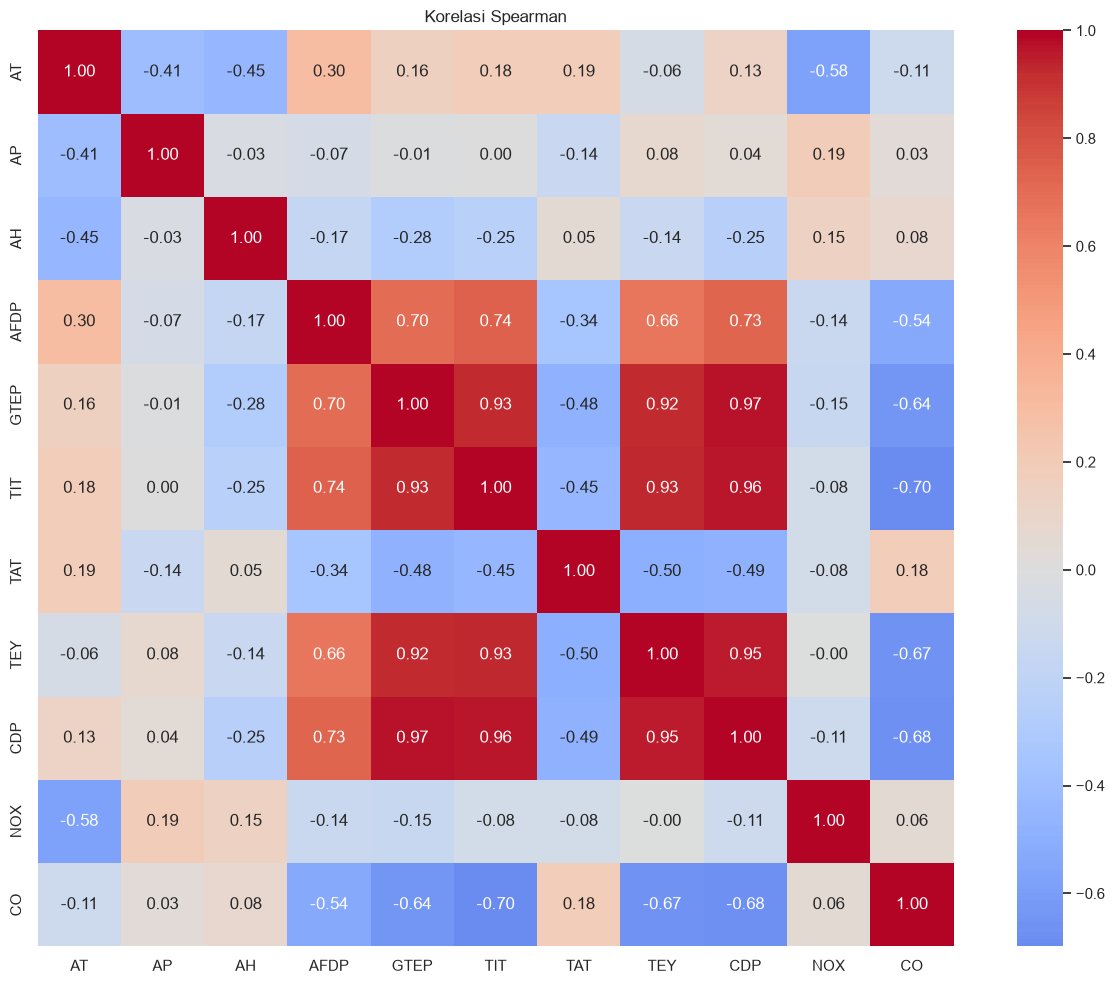


KORELASI SPEARMAN FITUR TERHADAP TARGET


,NOX,CO
AT,-0.580365,-0.114026
AP,0.194497,0.033200
GTEP,-0.154089,-0.639133
AH,0.149635,0.080805
AFDP,-0.140450,-0.536206
CDP,-0.108101,-0.675231
TAT,-0.084772,0.183890
TIT,-0.078099,-0.698435
TEY,-0.003652,-0.671618



STATISTIK TARGET PER TAHUN


NOX                                            CO          \
           mean   median        std     min     max      mean  median   
Year                                                                    
2011  67.575392  65.5420  10.683331  27.765  119.32  1.572486  1.1557   
2012  68.788965  67.2465  10.224937  41.777  119.89  2.361133  1.6363   
2013  70.007899  68.6510  12.048249  43.198  119.91  2.723031  1.7827   
2014  60.066886  59.2785   9.971729  27.183  118.47  2.081103  1.6553   
2015  59.890509  56.8385  11.132464  25.905  119.68  3.129986  2.5334   

                                  
           std       min     max  
Year                              
2011  1.845442  0.000388  43.622  
2012  2.474116  0.007505  44.103  
2013  2.363913  0.005033  35.045  
2014  2.006939  0.001640  34.820  
2015  2.234962  0.212800  41.097

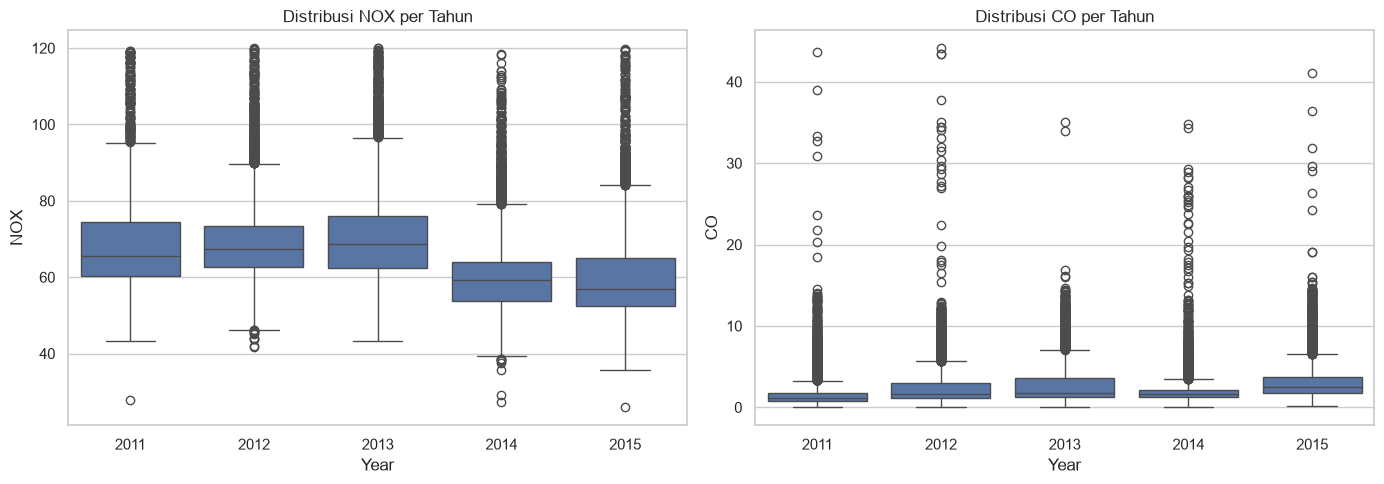

In [12]:
# Distribusi target dengan skala asli dan log1p
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, target in enumerate(TARGETS):
    sns.histplot(df[target].dropna(), bins=60, kde=True, ax=axes[row, 0])
    axes[row, 0].set_title(f"Distribusi {target} - Skala Asli")
    sns.histplot(np.log1p(df[target].clip(lower=0).dropna()),
                 bins=60, kde=True, ax=axes[row, 1])
    axes[row, 1].set_title(f"Distribusi log1p({target})")
plt.tight_layout()
plt.show()

skew_table = df[TARGETS].agg(["mean", "median", "std", "min", "max", "skew"]).T
print("\nRINGKASAN DISTRIBUSI TARGET")
display(skew_table)

# Boxplot untuk memeriksa nilai ekstrem
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, target in zip(axes, TARGETS):
    sns.boxplot(x=df[target], ax=ax)
    ax.set_title(f"Boxplot {target}")
plt.tight_layout()
plt.show()

# Outlier IQR: hanya identifikasi, tidak otomatis dihapus/winsorize.
outlier_rows = []
for col in EXPECTED_COLUMNS:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "Variable": col,
        "Lower_IQR": lower,
        "Upper_IQR": upper,
        "Outlier_count": int(mask.sum()),
        "Outlier_percent": float(mask.mean() * 100)
    })
outlier_table = pd.DataFrame(outlier_rows).sort_values(
    "Outlier_percent", ascending=False
)
print("\nDETEKSI OUTLIER DENGAN IQR (bukan keputusan penghapusan)")
display(outlier_table)

# Korelasi Pearson dan Spearman
corr_pearson = df[EXPECTED_COLUMNS].corr(method="pearson")
corr_spearman = df[EXPECTED_COLUMNS].corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True)
plt.title("Korelasi Pearson")
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 10))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True)
plt.title("Korelasi Spearman")
plt.tight_layout()
plt.show()

# Hubungan masing-masing fitur dengan target
target_corr = df[FEATURES + TARGETS].corr(method="spearman")[TARGETS].loc[FEATURES]
print("\nKORELASI SPEARMAN FITUR TERHADAP TARGET")
display(target_corr.sort_values("NOX", key=lambda s: s.abs(), ascending=False))

# Perbandingan statistik target per tahun
year_summary = df.groupby("Year")[TARGETS].agg(["mean", "median", "std", "min", "max"])
print("\nSTATISTIK TARGET PER TAHUN")
display(year_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, target in zip(axes, TARGETS):
    sns.boxplot(data=df, x="Year", y=target, ax=ax)
    ax.set_title(f"Distribusi {target} per Tahun")
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# 3. KEPUTUSAN PREPROCESSING
# ============================================================
# Missing value: jika ada, median imputation dilakukan di dalam Pipeline.
# Outlier: tidak dibuang otomatis. Pada data emisi, nilai ekstrem dapat
# merepresentasikan kondisi operasi nyata. Evaluasi model akan menunjukkan
# apakah nilai ekstrem merusak performa.
#
# Imbalance: SMOTE tidak digunakan karena target bersifat kontinu (regresi).
# Untuk CO yang skewed, akan dibandingkan model target asli vs log1p.
# NOx menggunakan skala target asli.
#
# Scaling: StandardScaler hanya di-fit pada bagian training melalui Pipeline.
#
# Feature reduction: korelasi antarfitur diperiksa hanya dari data training
# pada setiap split. Fitur dengan korelasi absolut > 0.95 akan direduksi.
# Ini adalah pembanding sederhana dan transparan, bukan klaim bahwa fitur
# yang dihapus tidak penting secara fisik.

def reduce_correlated_features(X_train, threshold=0.95):
    """Mengembalikan fitur terpilih berdasarkan korelasi antarfitur train."""
    corr = X_train.corr(method="pearson").abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    drop_cols = [
        col for col in upper.columns
        if any(upper[col] > threshold)
    ]
    selected = [col for col in X_train.columns if col not in drop_cols]
    return selected, drop_cols

def make_splits(data):
    X = data[FEATURES]
    y_year = data["Year"]

    # Random splits
    idx = np.arange(len(data))
    idx_train_80, idx_test_20 = train_test_split(
        idx, test_size=0.20, random_state=RANDOM_STATE, shuffle=True
    )
    idx_train_70, idx_test_30 = train_test_split(
        idx, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
    )

    # Temporal/year-based split
    idx_train_year = np.where(data["Year"].isin([2011, 2012, 2013]))[0]
    idx_test_year = np.where(data["Year"].isin([2014, 2015]))[0]

    return {
        "Random_80_20": (idx_train_80, idx_test_20),
        "Random_70_30": (idx_train_70, idx_test_30),
        "Year_2011-2013_to_2014-2015": (idx_train_year, idx_test_year)
    }

SPLITS = make_splits(df)

print("\nRINGKASAN SPLIT")
for name, (tr, te) in SPLITS.items():
    print(f"{name}: train={len(tr):,} ({len(tr)/len(df):.1%}), "
          f"test={len(te):,} ({len(te)/len(df):.1%})")


RINGKASAN SPLIT
Random_80_20: train=29,386 (80.0%), test=7,347 (20.0%)
Random_70_30: train=25,713 (70.0%), test=11,020 (30.0%)
Year_2011-2013_to_2014-2015: train=22,191 (60.4%), test=14,542 (39.6%)


In [14]:
def build_models():
    return {
        "Linear_Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),
        "Ridge_Polynomial": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("poly", PolynomialFeatures(degree=2, include_bias=False)),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=10.0))
        ]),
        "SVR_RBF": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVR(kernel="rbf", C=10.0, epsilon=0.1))
        ]),
         "Decision_Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(
                max_depth=12, min_samples_split=10,
                min_samples_leaf=5, random_state=RANDOM_STATE
            ))
        ]),
        "Random_Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=300, min_samples_leaf=2,
                max_features=1.0, n_jobs=-1,
                random_state=RANDOM_STATE
            ))
        ]),
        "Gradient_Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(
                n_estimators=200, learning_rate=0.05,
                max_depth=2, loss="huber",
                random_state=RANDOM_STATE
            ))
        ])
    }

def transform_target(y, target):
    """CO memakai log1p; NOx tetap pada skala asli."""
    y = np.asarray(y, dtype=float)
    if target == "CO":
        if np.nanmin(y) < 0:
            raise ValueError("CO memiliki nilai negatif; log1p tidak dapat diterapkan.")
        return np.log1p(y)
    return y

def inverse_target(y_pred, target):
    y_pred = np.asarray(y_pred, dtype=float)
    if target == "CO":
        return np.maximum(np.expm1(y_pred), 0)
    return y_pred

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }
def manual_cv(estimator, X_train, y_train, target, n_splits=5):
    """5-fold CV; semua skor dihitung kembali pada satuan target asli."""
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    fold_results = []

    for fold, (fit_idx, val_idx) in enumerate(kf.split(X_train), start=1):
        model = clone(estimator)
        y_fit = transform_target(y_train.iloc[fit_idx], target)
        model.fit(X_train.iloc[fit_idx], y_fit)

        pred_transformed = model.predict(X_train.iloc[val_idx])
        pred = inverse_target(pred_transformed, target)
        scores = regression_metrics(y_train.iloc[val_idx], pred)
        scores["Fold"] = fold
        fold_results.append(scores)

    fold_df = pd.DataFrame(fold_results)
    summary = {}
    for metric in ["MAE", "RMSE", "R2"]:
        summary[f"CV_{metric}_mean"] = fold_df[metric].mean()
        summary[f"CV_{metric}_std"] = fold_df[metric].std(ddof=1)
    return summary, fold_df

In [15]:
# ============================================================
# 5. EKSPERIMEN ML: 2 TARGET x 3 SPLIT x 2 SET FITUR x 6 MODEL
# ============================================================
# Semua model dibandingkan pada:
# - fitur lengkap (9 fitur)
# - fitur tereduksi (korelasi antarfitur dihitung dari train split saja)
#
# Catatan: CV dilakukan hanya pada training portion setiap split.
# Data test tidak digunakan untuk memilih model atau preprocessing.

ml_results = []
ml_models_fitted = {}
feature_selection_log = []
cv_fold_details = []

for target in TARGETS:
    y_all = df[target]

    for split_name, (train_idx, test_idx) in SPLITS.items():
        X_train_full = df.iloc[train_idx][FEATURES].copy()
        X_test_full = df.iloc[test_idx][FEATURES].copy()
        y_train = y_all.iloc[train_idx].copy()
        y_test = y_all.iloc[test_idx].copy()

        selected_features, dropped_features = reduce_correlated_features(
            X_train_full, threshold=0.95
        )
        feature_selection_log.append({
            "Target": target,
            "Split": split_name,
            "Selected_features": selected_features,
            "Dropped_features": dropped_features
        })

        feature_sets = {
            "Full": FEATURES,
            "Reduced": selected_features
        }

        for feature_type, cols in feature_sets.items():
            X_train = X_train_full[cols].copy()
            X_test = X_test_full[cols].copy()

            for model_name, estimator in build_models().items():
                print(f"Running: {target} | {split_name} | "
                      f"{feature_type} | {model_name}")

                # 5-fold CV di data latih saja
                cv_summary, fold_df = manual_cv(
                    estimator, X_train.reset_index(drop=True),
                    y_train.reset_index(drop=True), target, n_splits=5
                )
                fold_df["Target"] = target
                fold_df["Split"] = split_name
                fold_df["Feature_Set"] = feature_type
                fold_df["Model"] = model_name
                cv_fold_details.append(fold_df)

                # Fit final estimator pada seluruh data latih split
                final_model = clone(estimator)
                y_train_transformed = transform_target(y_train, target)
                final_model.fit(X_train, y_train_transformed)

                pred_train = inverse_target(final_model.predict(X_train), target)
                pred_test = inverse_target(final_model.predict(X_test), target)

                train_scores = regression_metrics(y_train, pred_train)
                test_scores = regression_metrics(y_test, pred_test)

                row = {
                    "Target": target,
                    "Split": split_name,
                    "Feature_Set": feature_type,
                    "Model": model_name,
                    "N_train": len(X_train),
                    "N_test": len(X_test),
                    **cv_summary,
                    "Train_MAE": train_scores["MAE"],
                    "Train_RMSE": train_scores["RMSE"],
                    "Train_R2": train_scores["R2"],
                    "Test_MAE": test_scores["MAE"],
                    "Test_RMSE": test_scores["RMSE"],
                    "Test_R2": test_scores["R2"],
                    "R2_Train_minus_CV": train_scores["R2"] - cv_summary["CV_R2_mean"]
                }
                ml_results.append(row)

                key = (target, split_name, feature_type, model_name)
                ml_models_fitted[key] = {
                    "model": final_model,
                    "features": cols,
                    "X_test": X_test,
                    "y_test": y_test,
                    "pred_test": pred_test
                }

ml_results_df = pd.DataFrame(ml_results)
cv_folds_df = pd.concat(cv_fold_details, ignore_index=True)
feature_log_df = pd.DataFrame(feature_selection_log)

print("\nHASIL EKSPERIMEN ML")
display(ml_results_df.sort_values(
    ["Target", "Split", "Test_RMSE"]
).reset_index(drop=True))

print("\nLOG FITUR TEREDUKSI PER SPLIT")
display(feature_log_df)

# Simpan tabel hasil
ml_results_df.to_csv("hasil_ml_regresi.csv", index=False)
cv_folds_df.to_csv("detail_5fold_cv.csv", index=False)
feature_log_df.to_csv("log_feature_reduction.csv", index=False)


Running: NOX | Random_80_20 | Full | Linear_Regression
Running: NOX | Random_80_20 | Full | Ridge_Polynomial
Running: NOX | Random_80_20 | Full | SVR_RBF
Running: NOX | Random_80_20 | Full | Decision_Tree
Running: NOX | Random_80_20 | Full | Random_Forest
Running: NOX | Random_80_20 | Full | Gradient_Boosting
Running: NOX | Random_80_20 | Reduced | Linear_Regression
Running: NOX | Random_80_20 | Reduced | Ridge_Polynomial
Running: NOX | Random_80_20 | Reduced | SVR_RBF
Running: NOX | Random_80_20 | Reduced | Decision_Tree
Running: NOX | Random_80_20 | Reduced | Random_Forest
Running: NOX | Random_80_20 | Reduced | Gradient_Boosting
Running: NOX | Random_70_30 | Full | Linear_Regression
Running: NOX | Random_70_30 | Full | Ridge_Polynomial
Running: NOX | Random_70_30 | Full | SVR_RBF
Running: NOX | Random_70_30 | Full | Decision_Tree
Running: NOX | Random_70_30 | Full | Random_Forest
Running: NOX | Random_70_30 | Full | Gradient_Boosting
Running: NOX | Random_70_30 | Reduced | Linear_Re

,Target,Split,Feature_Set,Model,N_train,N_test,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std,Train_MAE,Train_RMSE,Train_R2,Test_MAE,Test_RMSE,Test_R2,R2_Train_minus_CV
0,CO,Random_70_30,Full,Random_Forest,25713,11020,0.488009,0.016894,1.160477,0.166308,0.738241,0.057935,0.218950,0.733248,0.896047,0.466836,1.054337,0.777538,0.157806
1,CO,Random_70_30,Reduced,Random_Forest,25713,11020,0.488068,0.017912,1.153040,0.159089,0.741599,0.055169,0.222519,0.739293,0.894326,0.467209,1.059922,0.775175,0.152726
2,CO,Random_70_30,Full,SVR_RBF,25713,11020,0.534233,0.007151,1.249269,0.205654,0.694722,0.083807,0.500081,1.068474,0.779268,0.510192,1.110728,0.753105,0.084546
3,CO,Random_70_30,Reduced,SVR_RBF,25713,11020,0.547609,0.007487,1.262792,0.190601,0.689054,0.075172,0.511062,1.072951,0.777415,0.524055,1.153537,0.733707,0.088361
4,CO,Random_70_30,Full,Decision_Tree,25713,11020,0.582923,0.016069,1.274792,0.158337,0.684426,0.060182,0.438313,0.940714,0.828899,0.576054,1.256903,0.683845,0.144474
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,NOX,Year_2011-2013_to_2014-2015,Full,SVR_RBF,22191,14542,2.962703,0.041404,4.677718,0.122648,0.820070,0.010845,2.880705,4.589100,0.827085,12.861366,14.488314,-0.876447,0.007015
68,NOX,Year_2011-2013_to_2014-2015,Reduced,Linear_Regression,22191,14542,5.719729,0.050895,8.162460,0.117448,0.452629,0.011122,5.717239,8.158791,0.453450,13.272831,14.765317,-0.948885,0.000822
69,NOX,Year_2011-2013_to_2014-2015,Full,Ridge_Polynomial,22191,14542,4.065418,0.045249,5.892537,0.133339,0.714611,0.013185,4.021801,5.843226,0.719661,13.567734,15.135597,-1.047857,0.005050
70,NOX,Year_2011-2013_to_2014-2015,Reduced,SVR_RBF,22191,14542,2.977986,0.042308,4.699938,0.118146,0.818383,0.010188,2.889356,4.601288,0.826165,13.484673,15.156306,-1.053465,0.007782



LOG FITUR TEREDUKSI PER SPLIT


,Target,Split,Selected_features,Dropped_features
0,NOX,Random_80_20,"[AT, AP, AH, AFDP, GTEP, TIT, TAT]","[TEY, CDP]"
1,NOX,Random_70_30,"[AT, AP, AH, AFDP, GTEP, TIT, TAT]","[TEY, CDP]"
2,NOX,Year_2011-2013_to_2014-2015,"[AT, AP, AH, AFDP, GTEP, TIT, TAT]","[TEY, CDP]"
3,CO,Random_80_20,"[AT, AP, AH, AFDP, GTEP, TIT, TAT]","[TEY, CDP]"
4,CO,Random_70_30,"[AT, AP, AH, AFDP, GTEP, TIT, TAT]","[TEY, CDP]"
5,CO,Year_2011-2013_to_2014-2015,"[AT, AP, AH, AFDP, GTEP, TIT, TAT]","[TEY, CDP]"


In [20]:

# Pemeriksaan nama kolom secara detail
print("Jumlah kolom:", len(ml_results_df.columns))

for i, col in enumerate(ml_results_df.columns):
    print(i, repr(col))

print("\nPemeriksaan kolom RMSE:")
for col in ml_results_df.columns:
    if "RMSE" in str(col):
        print("Ditemukan:", repr(col))

print("\nApakah kolom tersedia?")
print("CV_RMSE_mean:", "CV_RMSE_mean" in ml_results_df.columns)
print("Test_RMSE:", "Test_RMSE" in ml_results_df.columns)


Jumlah kolom: 20
0 'Target'
1 'Split'
2 'Feature_Set'
3 'Model'
4 'N_train'
5 'N_test'
6 'CV_MAE_mean'
7 'CV_MAE_std'
8 'CV_RMSE_mean'
9 'CV_RMSE_std'
10 'CV_R2_mean'
11 'CV_R2_std'
12 'Train_MAE'
13 'Train_RMSE'
14 'Train_R2'
15 'Test_MAE'
16 'Test_RMSE'
17 'Test_R2'
18 'R2_Train_minus_CV'
19 'Fit_Diagnosis'

Pemeriksaan kolom RMSE:
Ditemukan: 'CV_RMSE_mean'
Ditemukan: 'CV_RMSE_std'
Ditemukan: 'Train_RMSE'
Ditemukan: 'Test_RMSE'

Apakah kolom tersedia?
CV_RMSE_mean: True
Test_RMSE: True


In [22]:

# =====================================================
# FIX DIAGNOSIS FIT
# =====================================================

# 1. Pastikan DataFrame memiliki kolom yang diperlukan
print("CV_RMSE_mean:", ml_results_df["CV_RMSE_mean"].head())
print("Test_RMSE:", ml_results_df["Test_RMSE"].head())

# 2. Buat salinan DataFrame
diagnosis_df = ml_results_df.copy()

# 3. Pastikan tipe kolom numerik
diagnosis_df["CV_RMSE_mean"] = pd.to_numeric(
    diagnosis_df["CV_RMSE_mean"], errors="coerce"
)

# 4. Urutkan berdasarkan CV_RMSE_mean saja
diagnosis_df = diagnosis_df.sort_values(
    by="CV_RMSE_mean",
    ascending=True
)

# 5. Tampilkan hasil
display(
    diagnosis_df[
        [
            "Target",
            "Split",
            "Feature_Set",
            "Model",
            "Train_R2",
            "CV_R2_mean",
            "Test_R2",
            "R2_Train_minus_CV",
            "Fit_Diagnosis"
        ]
    ].reset_index(drop=True)
)


CV_RMSE_mean: 0    8.093562
1    6.374557
2    5.287249
3    5.563719
4    4.285756
Name: CV_RMSE_mean, dtype: float64
Test_RMSE: 0    8.183204
1    6.370789
2    5.230662
3    5.468062
4    4.062243
Name: Test_RMSE, dtype: float64


,Target,Split,Feature_Set,Model,Train_R2,CV_R2_mean,Test_R2,R2_Train_minus_CV,Fit_Diagnosis
0,CO,Year_2011-2013_to_2014-2015,Reduced,Random_Forest,0.907887,0.764134,0.530332,0.143753,Relatif seimbang / perlu inspeksi
1,CO,Year_2011-2013_to_2014-2015,Full,Random_Forest,0.909677,0.763490,0.551124,0.146188,Relatif seimbang / perlu inspeksi
2,CO,Random_80_20,Reduced,Random_Forest,0.902996,0.744620,0.754686,0.158376,Indikasi overfitting
3,CO,Random_80_20,Full,Random_Forest,0.903765,0.741518,0.754942,0.162246,Indikasi overfitting
4,CO,Random_70_30,Reduced,Random_Forest,0.894326,0.741599,0.775175,0.152726,Indikasi overfitting
...,...,...,...,...,...,...,...,...,...
67,NOX,Random_80_20,Full,Linear_Regression,0.523321,0.522899,0.494665,0.000422,Relatif seimbang / perlu inspeksi
68,NOX,Random_70_30,Full,Linear_Regression,0.523917,0.522728,0.502385,0.001189,Relatif seimbang / perlu inspeksi
69,NOX,Year_2011-2013_to_2014-2015,Reduced,Linear_Regression,0.453450,0.452629,-0.948885,0.000822,Indikasi underfitting
70,NOX,Random_80_20,Reduced,Linear_Regression,0.442981,0.442639,0.422974,0.000342,Indikasi underfitting


In [23]:

# =====================================================
# RINGKASAN MODEL TERBAIK SETIAP TARGET DAN SPLIT
# =====================================================

best_summary = (
    ml_results_df
    .sort_values("CV_RMSE_mean", ascending=True)
    .groupby(["Target", "Split"], as_index=False)
    .first()
)

columns_summary = [
    "Target",
    "Split",
    "Feature_Set",
    "Model",
    "CV_MAE_mean",
    "CV_MAE_std",
    "CV_RMSE_mean",
    "CV_RMSE_std",
    "CV_R2_mean",
    "CV_R2_std",
    "Test_MAE",
    "Test_RMSE",
    "Test_R2",
    "Fit_Diagnosis"
]

display(
    best_summary[columns_summary]
    .reset_index(drop=True)
)


,Target,Split,Feature_Set,Model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std,Test_MAE,Test_RMSE,Test_R2,Fit_Diagnosis
0,CO,Random_70_30,Reduced,Random_Forest,0.488068,0.017912,1.153040,0.159089,0.741599,0.055169,0.467209,1.059922,0.775175,Indikasi overfitting
1,CO,Random_80_20,Reduced,Random_Forest,0.474926,0.008915,1.133906,0.072802,0.744620,0.020172,0.475808,1.154957,0.754686,Indikasi overfitting
2,CO,Year_2011-2013_to_2014-2015,Reduced,Random_Forest,0.476894,0.012955,1.114170,0.072898,0.764134,0.023793,0.891511,1.500419,0.530332,Relatif seimbang / perlu inspeksi
3,NOX,Random_70_30,Full,Random_Forest,2.804685,0.021375,4.390106,0.086344,0.860185,0.010792,2.642189,4.174911,0.867901,Relatif seimbang / perlu inspeksi
4,NOX,Random_80_20,Full,Random_Forest,2.720098,0.030606,4.285756,0.083983,0.866206,0.003920,2.593324,4.062243,0.875473,Relatif seimbang / perlu inspeksi
5,NOX,Year_2011-2013_to_2014-2015,Full,Random_Forest,2.563321,0.039986,3.951279,0.111697,0.871628,0.007809,10.652711,12.190596,-0.328466,Relatif seimbang / perlu inspeksi



MODEL TERBAIK BERDASARKAN 5-FOLD CV


,Target,Split,Feature_Set,Model,CV_RMSE_mean,CV_RMSE_std,Test_RMSE,Test_MAE,Test_R2
0,CO,Random_70_30,Reduced,Random_Forest,1.153040,0.159089,1.059922,0.467209,0.775175
1,CO,Random_80_20,Reduced,Random_Forest,1.133906,0.072802,1.154957,0.475808,0.754686
2,CO,Year_2011-2013_to_2014-2015,Reduced,Random_Forest,1.114170,0.072898,1.500419,0.891511,0.530332
3,NOX,Random_70_30,Full,Random_Forest,4.390106,0.086344,4.174911,2.642189,0.867901
4,NOX,Random_80_20,Full,Random_Forest,4.285756,0.083983,4.062243,2.593324,0.875473
5,NOX,Year_2011-2013_to_2014-2015,Full,Random_Forest,3.951279,0.111697,12.190596,10.652711,-0.328466


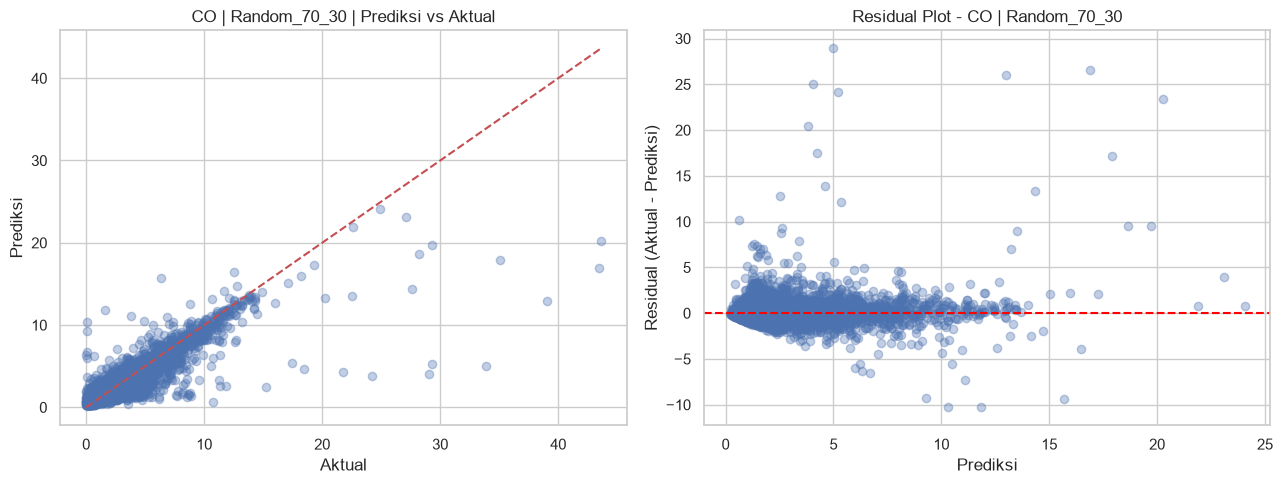

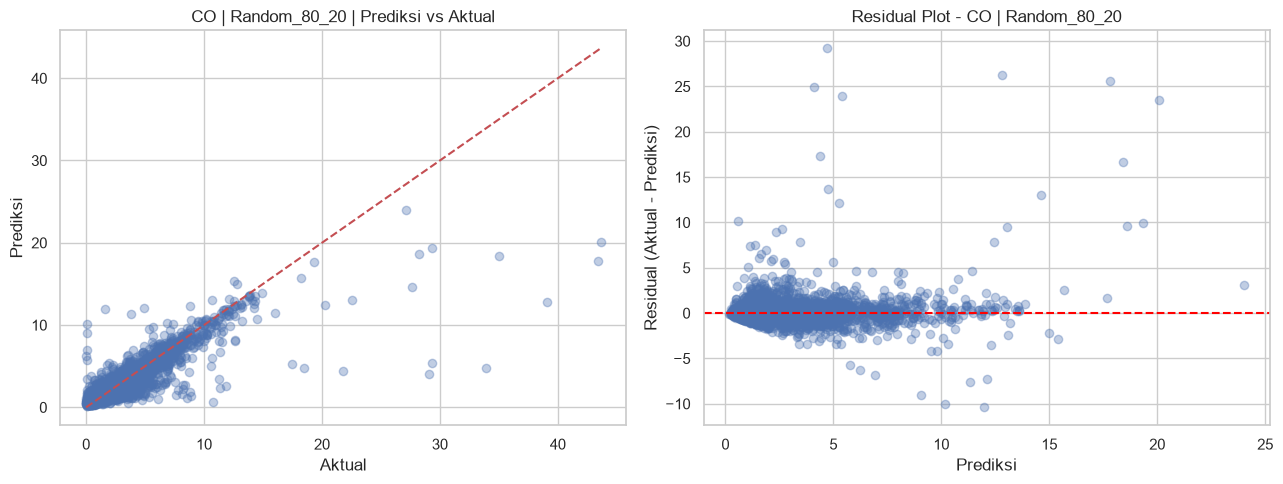

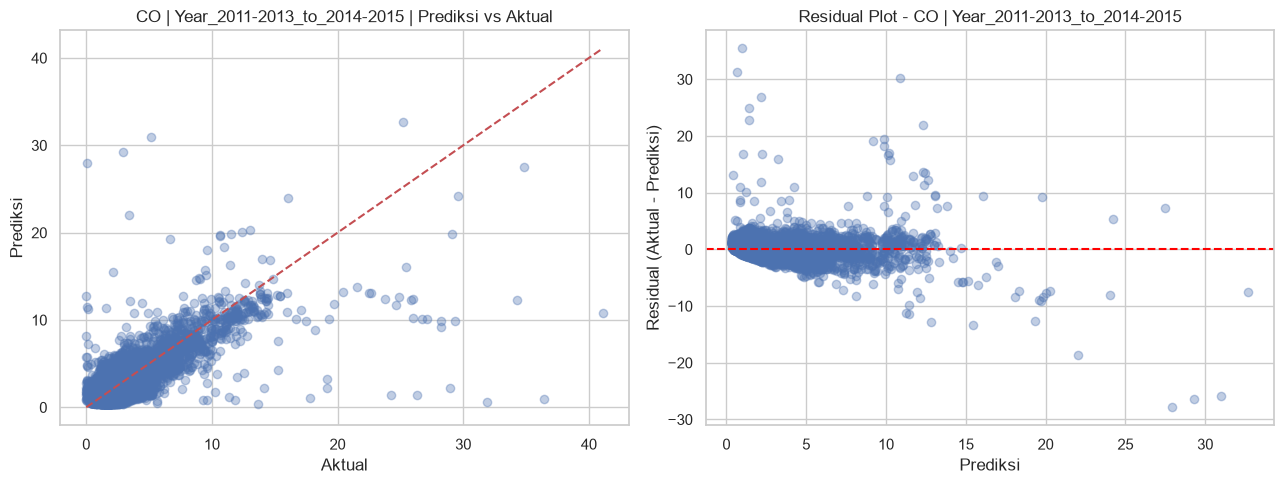

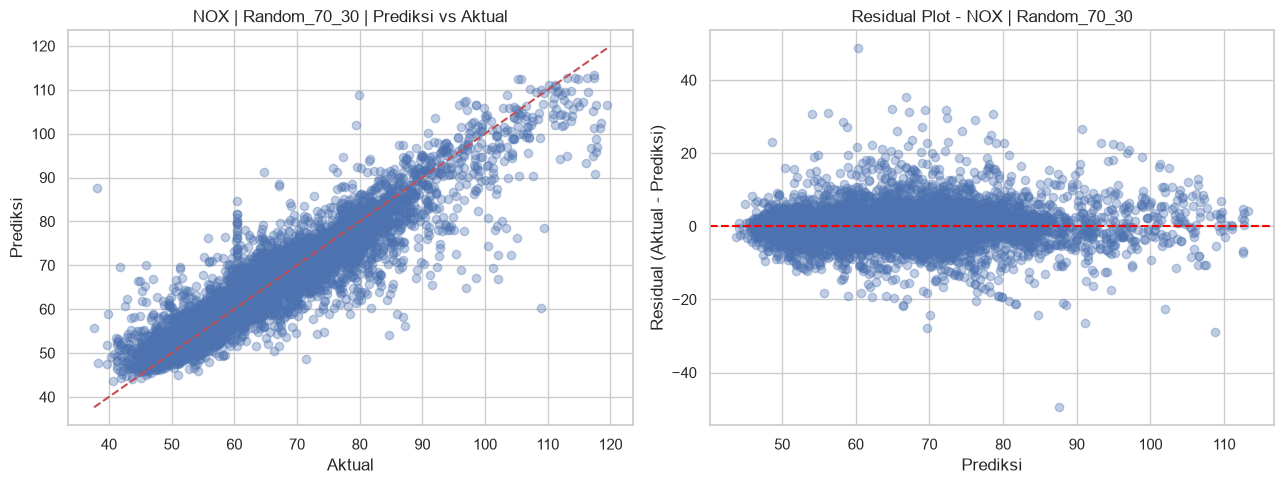

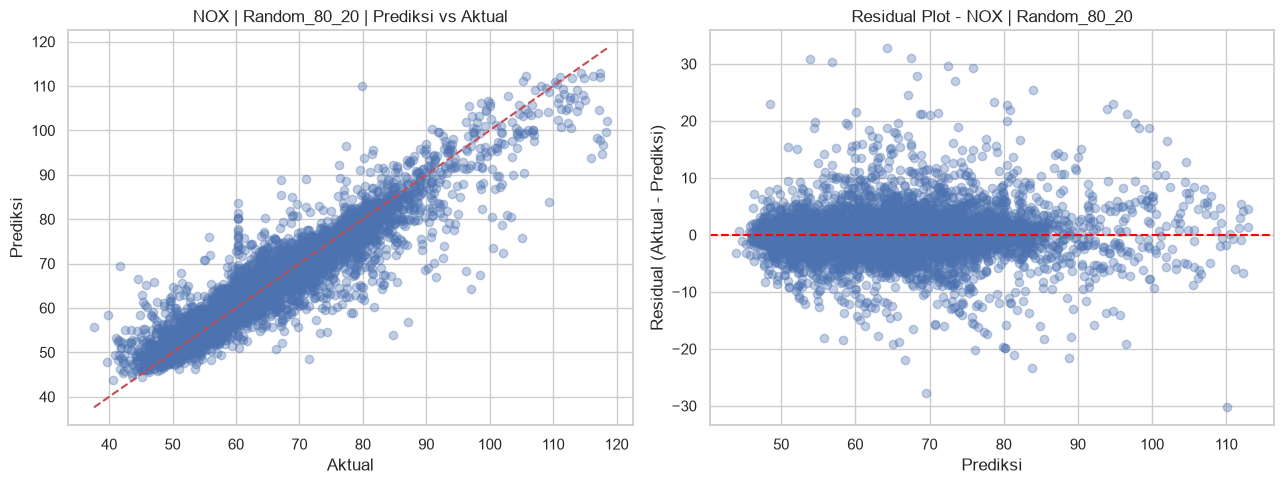

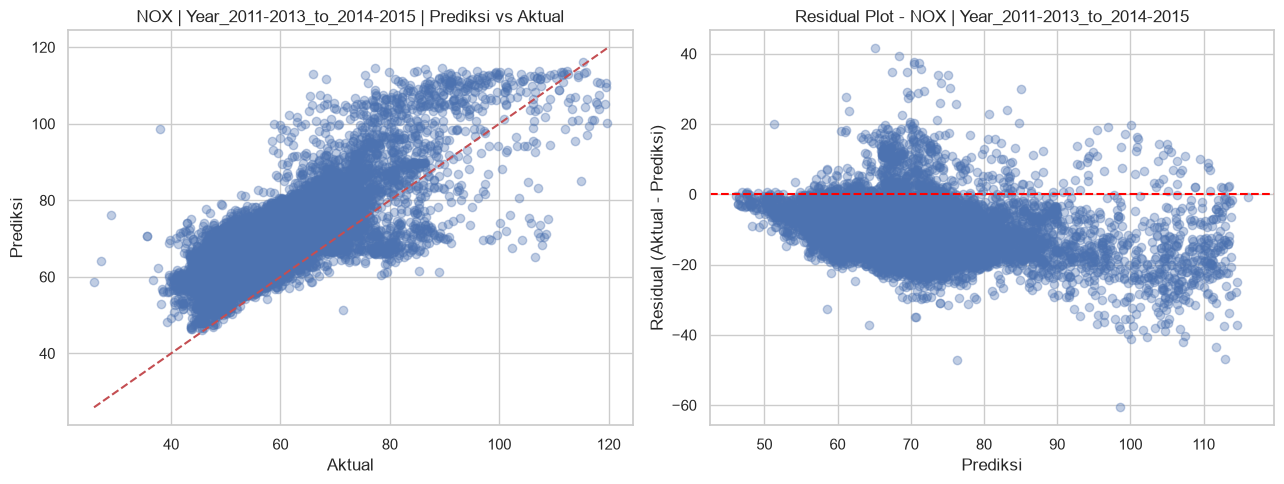

In [24]:
# ============================================================
# 7. VISUALISASI PREDIKSI VS AKTUAL DAN RESIDUAL
# ============================================================
# Pilih model terbaik berdasarkan CV_RMSE_mean pada setiap target/split.
# Test set tidak digunakan untuk memilih model.
best_ml_rows = (
    ml_results_df.sort_values("CV_RMSE_mean")
    .groupby(["Target", "Split"], as_index=False)
    .first()
)
print("\nMODEL TERBAIK BERDASARKAN 5-FOLD CV")
display(best_ml_rows[
    ["Target", "Split", "Feature_Set", "Model",
     "CV_RMSE_mean", "CV_RMSE_std", "Test_RMSE", "Test_MAE", "Test_R2"]
])

for _, row in best_ml_rows.iterrows():
    key = (row["Target"], row["Split"], row["Feature_Set"], row["Model"])
    item = ml_models_fitted[key]
    y_true = item["y_test"]
    y_pred = item["pred_test"]
    residual = y_true.to_numpy() - y_pred

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].scatter(y_true, y_pred, alpha=0.35)
    low = min(np.min(y_true), np.min(y_pred))
    high = max(np.max(y_true), np.max(y_pred))
    axes[0].plot([low, high], [low, high], "r--")
    axes[0].set_xlabel("Aktual")
    axes[0].set_ylabel("Prediksi")
    axes[0].set_title(
        f"{row['Target']} | {row['Split']} | Prediksi vs Aktual"
    )

    axes[1].scatter(y_pred, residual, alpha=0.35)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_xlabel("Prediksi")
    axes[1].set_ylabel("Residual (Aktual - Prediksi)")
    axes[1].set_title(f"Residual Plot - {row['Target']} | {row['Split']}")
    plt.tight_layout()
    plt.show()



PERMUTATION IMPORTANCE CO - MODEL ML TERBAIK (SPLIT TAHUN)


,Feature,RMSE_increase_mean,RMSE_increase_std
5,TIT,2.094498,0.027048
6,TAT,0.497857,0.025039
4,GTEP,0.205620,0.014841
3,AFDP,0.052207,0.006566
1,AP,-0.000180,0.002484
0,AT,-0.002584,0.009477
2,AH,-0.005964,0.002851


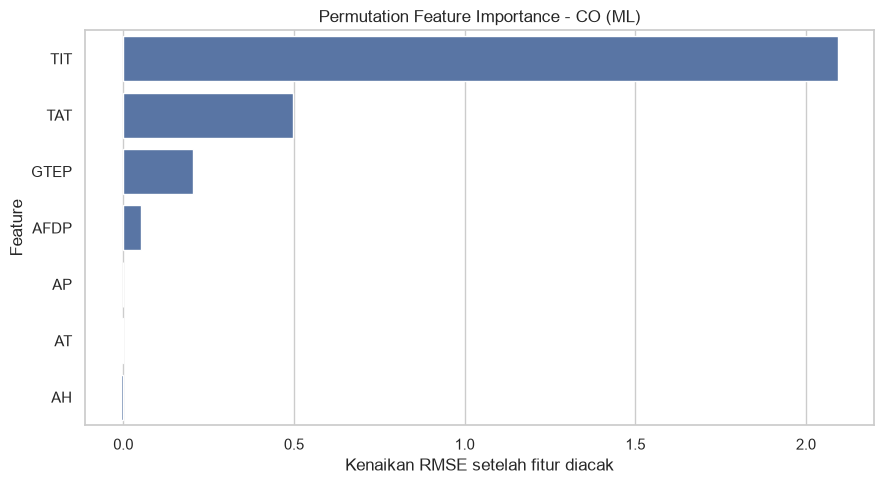

In [25]:
# ============================================================
# 8. ANALISIS PENGARUH FITUR PADA REGRESI CO
# ============================================================
# Untuk interpretasi utama CO, gunakan model terbaik pada split tahun
# berdasarkan CV. Permutation importance dihitung pada test tahun 2014-2015.
# Nilai importance = kenaikan RMSE ketika satu fitur diacak.
co_year_candidates = ml_results_df[
    (ml_results_df["Target"] == "CO") &
    (ml_results_df["Split"] == "Year_2011-2013_to_2014-2015")
]
best_co_year = co_year_candidates.sort_values("CV_RMSE_mean").iloc[0]
co_key = (
    best_co_year["Target"], best_co_year["Split"],
    best_co_year["Feature_Set"], best_co_year["Model"]
)
co_item = ml_models_fitted[co_key]

def manual_permutation_importance(model, X, y, target, repeats=10):
    baseline_pred = inverse_target(model.predict(X), target)
    baseline_rmse = np.sqrt(mean_squared_error(y, baseline_pred))
    rng = np.random.default_rng(RANDOM_STATE)
    records = []

    for col in X.columns:
        increases = []
        for _ in range(repeats):
            X_perm = X.copy()
            X_perm[col] = rng.permutation(X_perm[col].to_numpy())
            pred = inverse_target(model.predict(X_perm), target)
            perm_rmse = np.sqrt(mean_squared_error(y, pred))
            increases.append(perm_rmse - baseline_rmse)
        records.append({
            "Feature": col,
            "RMSE_increase_mean": np.mean(increases),
            "RMSE_increase_std": np.std(increases, ddof=1)
        })
    return pd.DataFrame(records).sort_values(
        "RMSE_increase_mean", ascending=False
    )

co_perm = manual_permutation_importance(
    co_item["model"], co_item["X_test"], co_item["y_test"], "CO"
)
print("\nPERMUTATION IMPORTANCE CO - MODEL ML TERBAIK (SPLIT TAHUN)")
display(co_perm)

plt.figure(figsize=(9, 5))
sns.barplot(data=co_perm, x="RMSE_increase_mean", y="Feature")
plt.title("Permutation Feature Importance - CO (ML)")
plt.xlabel("Kenaikan RMSE setelah fitur diacak")
plt.tight_layout()
plt.show()


In [26]:
# 9. MLP / ANN - 3 ARSITEKTUR x 2 LEARNING RATE
# ============================================================
# TensorFlow/Keras digunakan agar tersedia Dropout, L2, EarlyStopping,
# dan kurva loss train-validation.
#
# Tiga arsitektur:
# A1: 64
# A2: 128 -> 64
# A3: 128 -> 64 -> 32
#
# Dua learning rate: 0.001 dan 0.0003
# Optimizer: Adam
# Regularisasi: Dropout + L2 + EarlyStopping
#
# Untuk menghindari leakage, scaler di-fit hanya pada inner-training.
# Inner-validation dipisahkan dari outer-training. Outer-test hanya untuk
# evaluasi akhir.

try:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import Dense, Dropout, Input
    from tensorflow.keras.regularizers import l2
    from tensorflow.keras.callbacks import EarlyStopping
except ImportError:
    raise ImportError(
        "TensorFlow belum terpasang. Jalankan: pip install tensorflow"
    )

tf.keras.utils.set_random_seed(RANDOM_STATE)

ARCHITECTURES = {
    "A1_64": [64],
    "A2_128_64": [128, 64],
    "A3_128_64_32": [128, 64, 32]
}
LEARNING_RATES = [0.001, 0.0003]

def build_mlp(input_dim, hidden_layers, learning_rate):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))

    for units in hidden_layers:
        model.add(Dense(
            units, activation="relu",
            kernel_regularizer=l2(1e-4)
        ))
        model.add(Dropout(0.20))

    model.add(Dense(1, activation="linear"))
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])
    return model

mlp_results = []
mlp_fitted = {}

for target in TARGETS:
    for split_name, (train_idx, test_idx) in SPLITS.items():
        X_outer_train = df.iloc[train_idx][FEATURES].copy()
        X_outer_test = df.iloc[test_idx][FEATURES].copy()
        y_outer_train = df.iloc[train_idx][target].copy()
        y_outer_test = df.iloc[test_idx][target].copy()

        # Inner validation hanya diambil dari outer-training.
        inner_train_idx, inner_val_idx = train_test_split(
            np.arange(len(X_outer_train)),
            test_size=0.20,
            random_state=RANDOM_STATE,
            shuffle=True
        )

        X_inner_train = X_outer_train.iloc[inner_train_idx]
        X_inner_val = X_outer_train.iloc[inner_val_idx]
        y_inner_train = y_outer_train.iloc[inner_train_idx]
        y_inner_val = y_outer_train.iloc[inner_val_idx]

        # Fit scaler hanya pada inner-training
        imputer = SimpleImputer(strategy="median")
        scaler = StandardScaler()

        Xtr_imp = imputer.fit_transform(X_inner_train)
        Xval_imp = imputer.transform(X_inner_val)
        Xtest_imp = imputer.transform(X_outer_test)

        Xtr = scaler.fit_transform(Xtr_imp)
        Xval = scaler.transform(Xval_imp)
        Xtest = scaler.transform(Xtest_imp)

        ytr = transform_target(y_inner_train, target)
        yval = transform_target(y_inner_val, target)

        for arch_name, hidden_layers in ARCHITECTURES.items():
            for lr in LEARNING_RATES:
                tf.keras.backend.clear_session()
                tf.keras.utils.set_random_seed(RANDOM_STATE)

                model = build_mlp(
                    input_dim=Xtr.shape[1],
                    hidden_layers=hidden_layers,
                    learning_rate=lr
                )
                early_stop = EarlyStopping(
                    monitor="val_loss",
                    patience=20,
                    min_delta=1e-5,
                    restore_best_weights=True
                )

                history = model.fit(
                    Xtr, ytr,
                    validation_data=(Xval, yval),
                    epochs=250,
                    batch_size=128,
                    callbacks=[early_stop],
                    verbose=0
                )

                # Evaluasi outer-test
                pred_test_transformed = model.predict(Xtest, verbose=0).ravel()
                pred_test = inverse_target(pred_test_transformed, target)
                test_scores = regression_metrics(y_outer_test, pred_test)

                # Train metric untuk indikasi fit (inner train)
                pred_train_transformed = model.predict(Xtr, verbose=0).ravel()
                pred_train = inverse_target(pred_train_transformed, target)
                train_scores = regression_metrics(y_inner_train, pred_train)

                best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
                params = int(model.count_params())

                result = {
                    "Target": target,
                    "Split": split_name,
                    "Architecture": arch_name,
                    "Hidden_layers": str(hidden_layers),
                    "Learning_rate": lr,
                    "Optimizer": "Adam",
                    "Dropout": 0.20,
                    "L2": 1e-4,
                    "Epochs_trained": len(history.history["loss"]),
                    "Best_epoch": best_epoch,
                    "Parameters": params,
                    "Train_RMSE": train_scores["RMSE"],
                    "Train_R2": train_scores["R2"],
                    "Validation_loss_best": float(np.min(history.history["val_loss"])),
                    "Test_MAE": test_scores["MAE"],
                    "Test_RMSE": test_scores["RMSE"],
                    "Test_R2": test_scores["R2"]
                }
                mlp_results.append(result)

                key = (target, split_name, arch_name, lr)
                mlp_fitted[key] = {
                    "model": model,
                    "imputer": imputer,
                    "scaler": scaler,
                    "X_test_scaled": Xtest,
                    "X_test_raw": X_outer_test,
                    "y_test": y_outer_test,
                    "pred_test": pred_test,
                    "history": history.history,
                    "features": FEATURES
                }

mlp_results_df = pd.DataFrame(mlp_results)
print("\nHASIL MLP")
display(mlp_results_df.sort_values(
    ["Target", "Split", "Validation_loss_best"]
).reset_index(drop=True))
mlp_results_df.to_csv("hasil_mlp_ann.csv", index=False)




HASIL MLP


,Target,Split,Architecture,Hidden_layers,Learning_rate,Optimizer,Dropout,L2,Epochs_trained,Best_epoch,Parameters,Train_RMSE,Train_R2,Validation_loss_best,Test_MAE,Test_RMSE,Test_R2
0,CO,Random_70_30,A2_128_64,"[128, 64]",0.0003,Adam,0.2,0.0001,250,241,9601,1.143497,0.744666,0.050433,0.496199,1.114480,0.751434
1,CO,Random_70_30,A2_128_64,"[128, 64]",0.0010,Adam,0.2,0.0001,172,152,9601,1.123749,0.753409,0.051273,0.494609,1.100879,0.757464
2,CO,Random_70_30,A3_128_64_32,"[128, 64, 32]",0.0003,Adam,0.2,0.0001,195,175,11649,1.093830,0.766365,0.051682,0.487909,1.070445,0.770689
3,CO,Random_70_30,A3_128_64_32,"[128, 64, 32]",0.0010,Adam,0.2,0.0001,132,112,11649,1.087351,0.769124,0.052670,0.491167,1.069121,0.771256
4,CO,Random_70_30,A1_64,[64],0.0010,Adam,0.2,0.0001,149,129,705,1.223642,0.707620,0.056841,0.537524,1.141947,0.739031
5,CO,Random_70_30,A1_64,[64],0.0003,Adam,0.2,0.0001,250,249,705,1.229198,0.704959,0.056971,0.542916,1.152229,0.734311
6,CO,Random_80_20,A2_128_64,"[128, 64]",0.0003,Adam,0.2,0.0001,250,231,9601,1.153125,0.740850,0.050204,0.516189,1.215695,0.728206
7,CO,Random_80_20,A3_128_64_32,"[128, 64, 32]",0.0003,Adam,0.2,0.0001,231,211,11649,1.114090,0.758099,0.050248,0.509814,1.177611,0.744969
8,CO,Random_80_20,A2_128_64,"[128, 64]",0.0010,Adam,0.2,0.0001,132,112,9601,1.181550,0.727917,0.052261,0.539318,1.269866,0.703445
9,CO,Random_80_20,A3_128_64_32,"[128, 64, 32]",0.0010,Adam,0.2,0.0001,65,45,11649,1.151128,0.741747,0.054628,0.532604,1.186931,0.740916



KONFIGURASI MLP TERBAIK BERDASARKAN VALIDATION LOSS


,Target,Split,Architecture,Hidden_layers,Learning_rate,Optimizer,Dropout,L2,Epochs_trained,Best_epoch,Parameters,Train_RMSE,Train_R2,Validation_loss_best,Test_MAE,Test_RMSE,Test_R2
0,CO,Random_70_30,A2_128_64,"[128, 64]",0.0003,Adam,0.2,0.0001,250,241,9601,1.143497,0.744666,0.050433,0.496199,1.114480,0.751434
1,CO,Random_80_20,A2_128_64,"[128, 64]",0.0003,Adam,0.2,0.0001,250,231,9601,1.153125,0.740850,0.050204,0.516189,1.215695,0.728206
2,CO,Year_2011-2013_to_2014-2015,A2_128_64,"[128, 64]",0.0003,Adam,0.2,0.0001,182,162,9601,1.192372,0.732195,0.056297,0.884434,1.410506,0.584936
3,NOX,Random_70_30,A3_128_64_32,"[128, 64, 32]",0.0010,Adam,0.2,0.0001,128,108,11649,4.904265,0.826215,24.558542,3.346243,4.881530,0.819401
4,NOX,Random_80_20,A3_128_64_32,"[128, 64, 32]",0.0010,Adam,0.2,0.0001,250,240,11649,4.210682,0.872078,17.297438,2.891593,4.298624,0.860559
5,NOX,Year_2011-2013_to_2014-2015,A3_128_64_32,"[128, 64, 32]",0.0010,Adam,0.2,0.0001,250,249,11649,4.146757,0.859616,17.183689,13.491972,16.641345,-1.475583


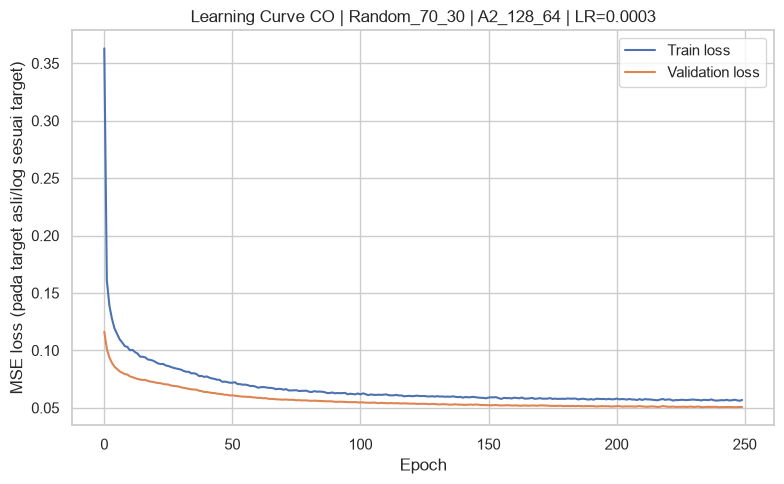

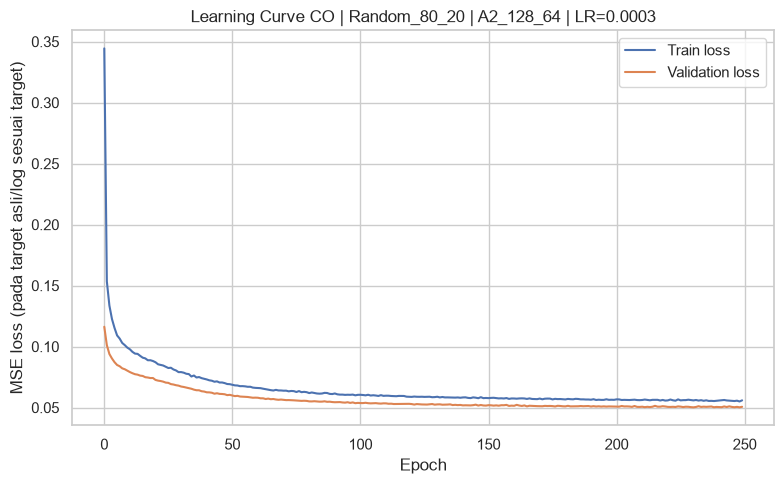

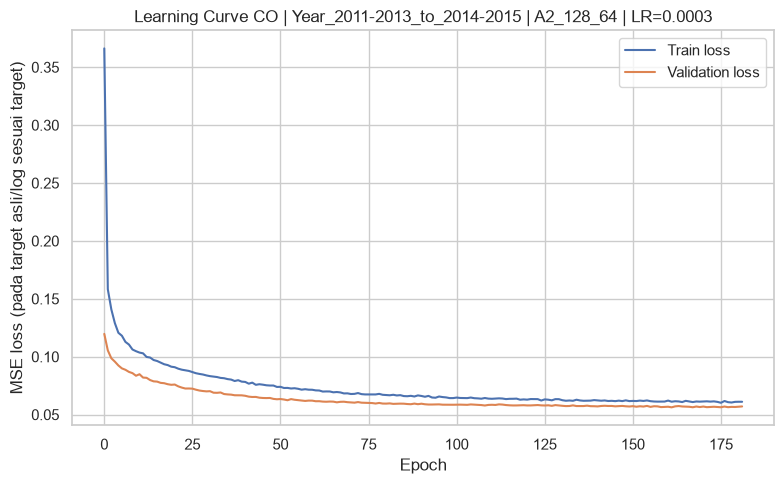

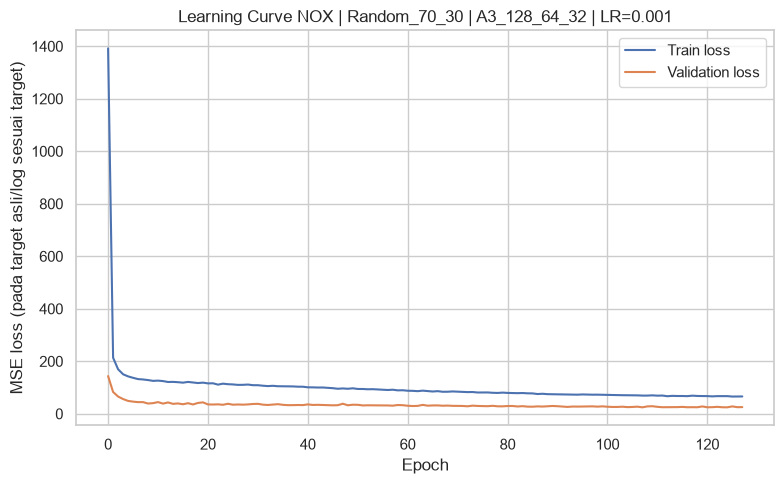

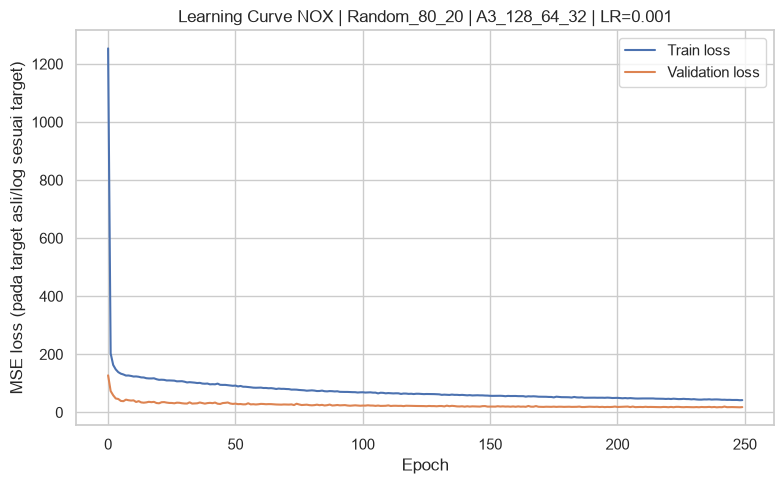

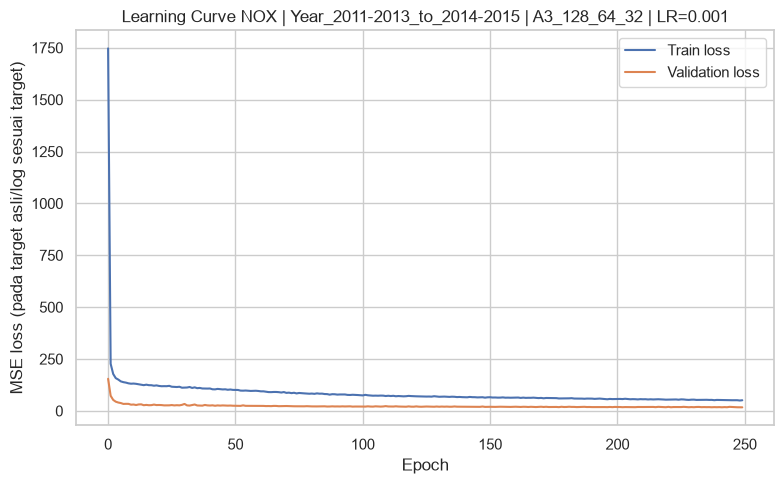

In [27]:
# ============================================================
# 10. KURVA LOSS TRAIN VS VALIDATION
# ============================================================
# Pilih konfigurasi berdasarkan validation loss, bukan test score.
best_mlp_rows = (
    mlp_results_df.sort_values("Validation_loss_best")
    .groupby(["Target", "Split"], as_index=False)
    .first()
)
print("\nKONFIGURASI MLP TERBAIK BERDASARKAN VALIDATION LOSS")
display(best_mlp_rows)

for _, row in best_mlp_rows.iterrows():
    key = (
        row["Target"], row["Split"],
        row["Architecture"], row["Learning_rate"]
    )
    history = mlp_fitted[key]["history"]

    plt.figure(figsize=(8, 5))
    plt.plot(history["loss"], label="Train loss")
    plt.plot(history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss (pada target asli/log sesuai target)")
    plt.title(
        f"Learning Curve {row['Target']} | {row['Split']} | "
        f"{row['Architecture']} | LR={row['Learning_rate']}"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()


In [28]:
# ============================================================
# 11. PERBANDINGAN MODEL ML TERBAIK VS MLP TERBAIK
# ============================================================
# Perbandingan dilakukan pada split dan target yang sama.
comparison_rows = []

for _, mlp_row in best_mlp_rows.iterrows():
    target = mlp_row["Target"]
    split_name = mlp_row["Split"]

    best_ml = (
        ml_results_df[
            (ml_results_df["Target"] == target) &
            (ml_results_df["Split"] == split_name)
        ].sort_values("CV_RMSE_mean").iloc[0]
    )

    comparison_rows.append({
        "Target": target,
        "Split": split_name,
        "Best_ML_Model": best_ml["Model"],
        "Best_ML_Feature_Set": best_ml["Feature_Set"],
        "ML_Test_MAE": best_ml["Test_MAE"],
        "ML_Test_RMSE": best_ml["Test_RMSE"],
        "ML_Test_R2": best_ml["Test_R2"],
        "Best_MLP_Architecture": mlp_row["Architecture"],
        "MLP_Learning_Rate": mlp_row["Learning_rate"],
        "MLP_Test_MAE": mlp_row["Test_MAE"],
        "MLP_Test_RMSE": mlp_row["Test_RMSE"],
        "MLP_Test_R2": mlp_row["Test_R2"]
    })

comparison_df = pd.DataFrame(comparison_rows)
print("\nPERBANDINGAN ML VS MLP")
display(comparison_df)
comparison_df.to_csv("perbandingan_ml_vs_mlp.csv", index=False)



PERBANDINGAN ML VS MLP


,Target,Split,Best_ML_Model,Best_ML_Feature_Set,ML_Test_MAE,ML_Test_RMSE,ML_Test_R2,Best_MLP_Architecture,MLP_Learning_Rate,MLP_Test_MAE,MLP_Test_RMSE,MLP_Test_R2
0,CO,Random_70_30,Random_Forest,Reduced,0.467209,1.059922,0.775175,A2_128_64,0.0003,0.496199,1.114480,0.751434
1,CO,Random_80_20,Random_Forest,Reduced,0.475808,1.154957,0.754686,A2_128_64,0.0003,0.516189,1.215695,0.728206
2,CO,Year_2011-2013_to_2014-2015,Random_Forest,Reduced,0.891511,1.500419,0.530332,A2_128_64,0.0003,0.884434,1.410506,0.584936
3,NOX,Random_70_30,Random_Forest,Full,2.642189,4.174911,0.867901,A3_128_64_32,0.0010,3.346243,4.881530,0.819401
4,NOX,Random_80_20,Random_Forest,Full,2.593324,4.062243,0.875473,A3_128_64_32,0.0010,2.891593,4.298624,0.860559
5,NOX,Year_2011-2013_to_2014-2015,Random_Forest,Full,10.652711,12.190596,-0.328466,A3_128_64_32,0.0010,13.491972,16.641345,-1.475583



MLP PERMUTATION IMPORTANCE - CO


,Feature,RMSE_increase_mean,RMSE_increase_std
5,TIT,0.682206,0.011952
7,TEY,0.666474,0.012938
6,TAT,0.492661,0.014214
4,GTEP,0.453643,0.011616
0,AT,0.092699,0.007480
8,CDP,0.059962,0.002338
3,AFDP,0.045111,0.005560
2,AH,0.014598,0.003050
1,AP,-0.013377,0.003632


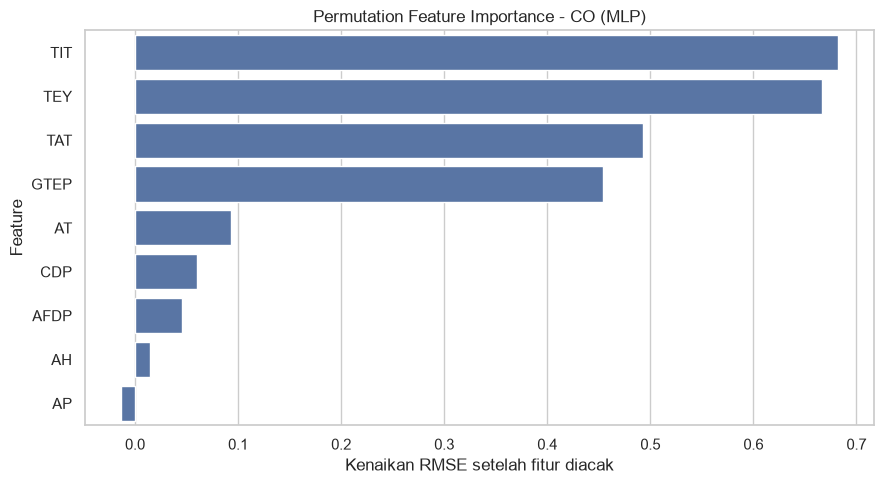

In [29]:
# ============================================================
# 12. PERMUTATION FEATURE IMPORTANCE BERBASIS MLP
# ============================================================
# Importance dihitung pada outer-test untuk interpretasi model terpilih.
# Metrik dasar: RMSE dalam satuan fisik. Semakin besar kenaikan RMSE setelah
# fitur diacak, semakin besar kontribusi prediktif fitur tersebut.
# Ini adalah interpretasi prediktif, bukan bukti sebab-akibat.

def mlp_permutation_importance(model, imputer, scaler, X_raw, y_true,
                               target, repeats=10):
    X_base = pd.DataFrame(X_raw).copy()
    base_scaled = scaler.transform(imputer.transform(X_base))
    base_pred = inverse_target(
        model.predict(base_scaled, verbose=0).ravel(), target
    )
    base_rmse = np.sqrt(mean_squared_error(y_true, base_pred))

    rng = np.random.default_rng(RANDOM_STATE)
    records = []

    for col in X_base.columns:
        increases = []
        for _ in range(repeats):
            X_perm = X_base.copy()
            X_perm[col] = rng.permutation(X_perm[col].to_numpy())
            X_perm_scaled = scaler.transform(imputer.transform(X_perm))
            pred = inverse_target(
                model.predict(X_perm_scaled, verbose=0).ravel(), target
            )
            perm_rmse = np.sqrt(mean_squared_error(y_true, pred))
            increases.append(perm_rmse - base_rmse)

        records.append({
            "Feature": col,
            "RMSE_increase_mean": np.mean(increases),
            "RMSE_increase_std": np.std(increases, ddof=1)
        })

    return pd.DataFrame(records).sort_values(
        "RMSE_increase_mean", ascending=False
    )

# Fokus interpretasi utama: CO pada split tahun.
co_mlp_best_row = best_mlp_rows[
    (best_mlp_rows["Target"] == "CO") &
    (best_mlp_rows["Split"] == "Year_2011-2013_to_2014-2015")
].iloc[0]

co_mlp_key = (
    co_mlp_best_row["Target"],
    co_mlp_best_row["Split"],
    co_mlp_best_row["Architecture"],
    co_mlp_best_row["Learning_rate"]
)
co_mlp_item = mlp_fitted[co_mlp_key]

co_mlp_perm = mlp_permutation_importance(
    co_mlp_item["model"],
    co_mlp_item["imputer"],
    co_mlp_item["scaler"],
    co_mlp_item["X_test_raw"],
    co_mlp_item["y_test"],
    "CO"
)
print("\nMLP PERMUTATION IMPORTANCE - CO")
display(co_mlp_perm)

plt.figure(figsize=(9, 5))
sns.barplot(data=co_mlp_perm, x="RMSE_increase_mean", y="Feature")
plt.title("Permutation Feature Importance - CO (MLP)")
plt.xlabel("Kenaikan RMSE setelah fitur diacak")
plt.tight_layout()
plt.show()


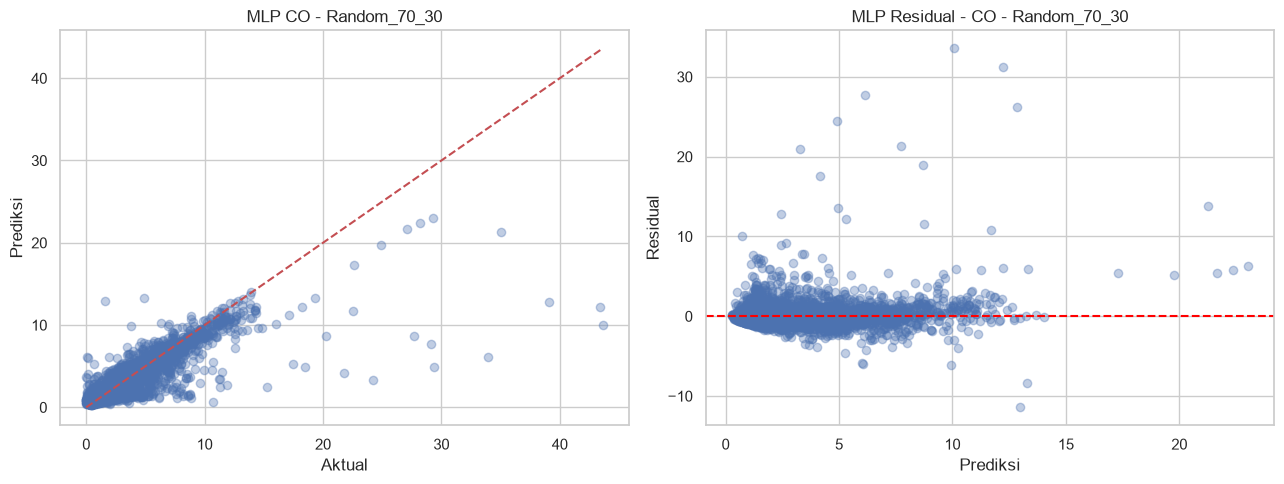

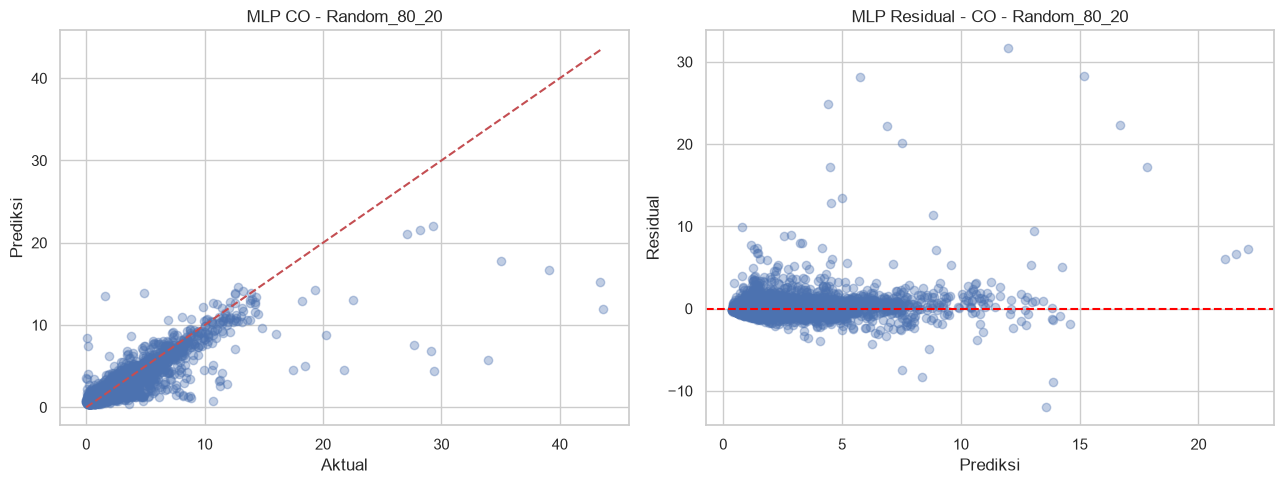

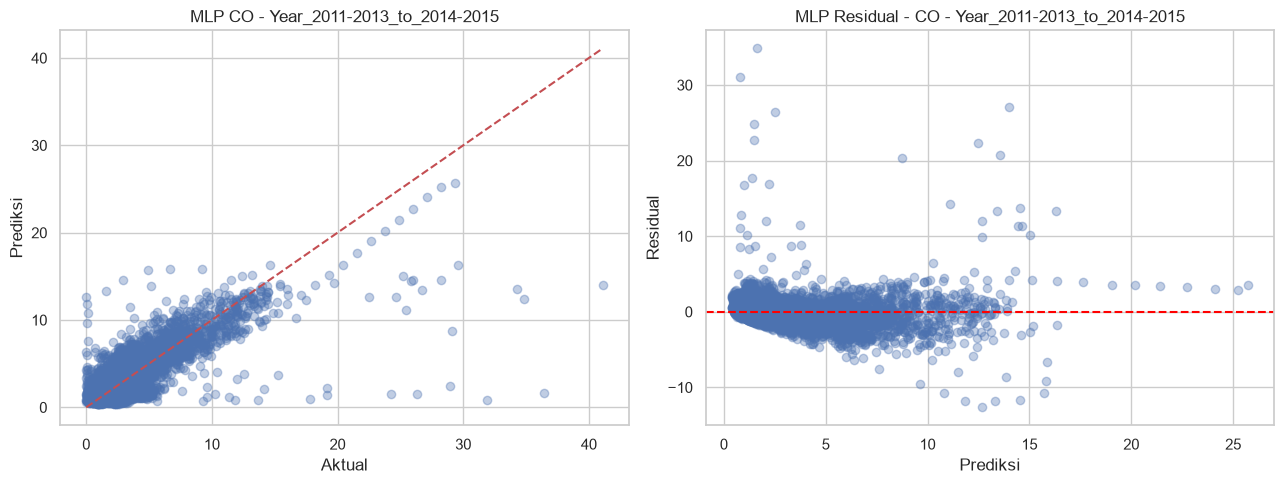

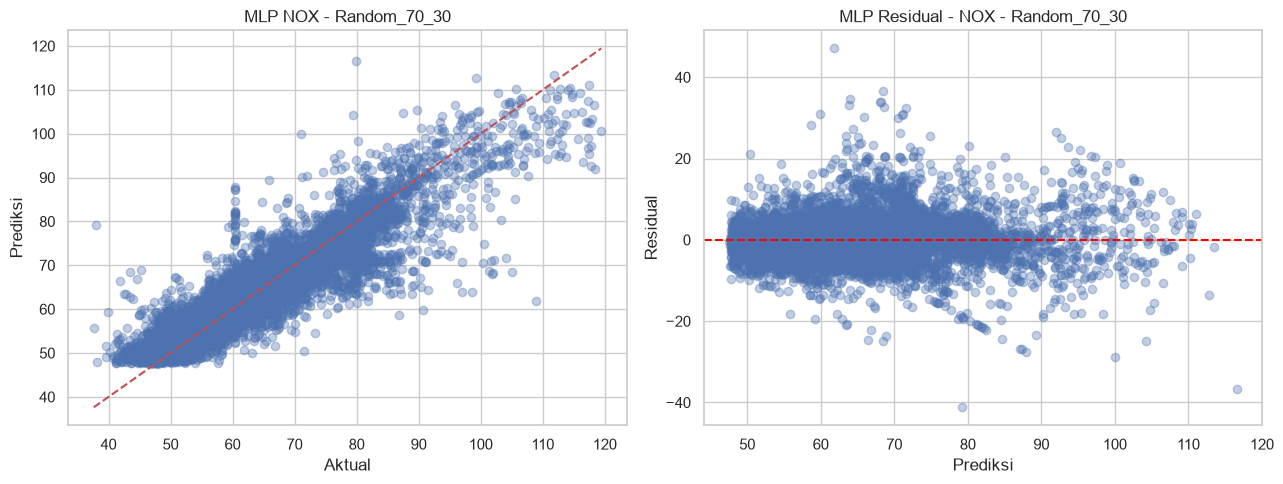

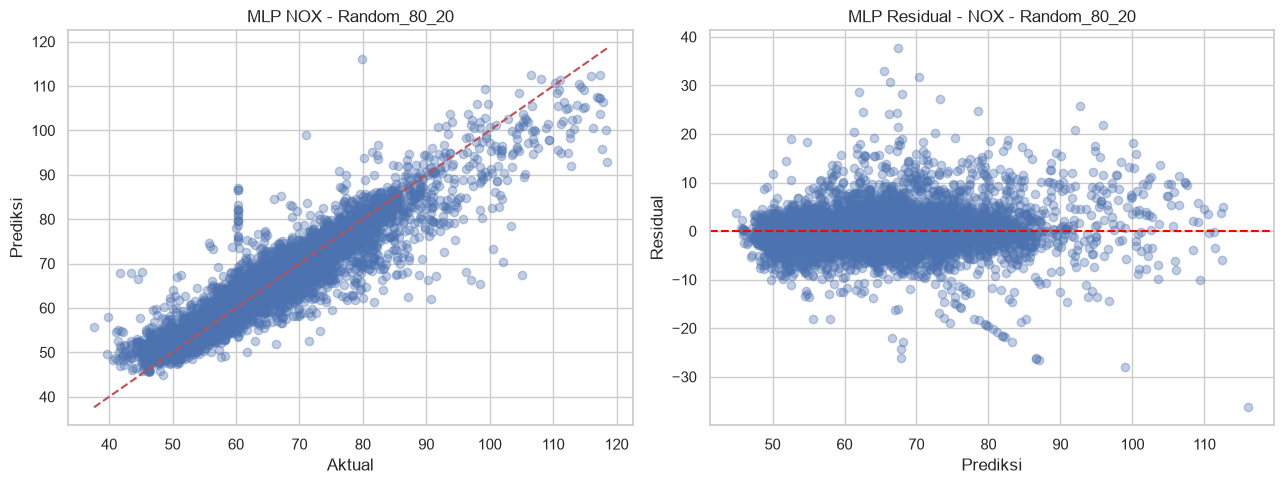

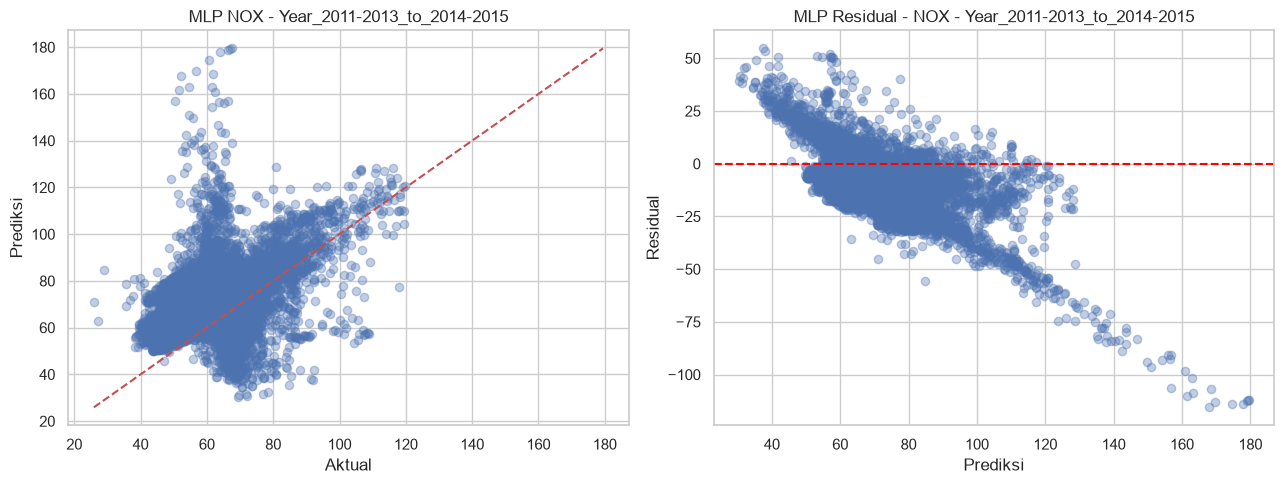

In [30]:
# ============================================================
# 13. VISUALISASI PREDIKSI VS AKTUAL & RESIDUAL UNTUK MLP
# ============================================================
for _, row in best_mlp_rows.iterrows():
    key = (
        row["Target"], row["Split"],
        row["Architecture"], row["Learning_rate"]
    )
    item = mlp_fitted[key]
    y_true = item["y_test"].to_numpy()
    y_pred = item["pred_test"]
    residual = y_true - y_pred

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].scatter(y_true, y_pred, alpha=0.35)
    low = min(y_true.min(), y_pred.min())
    high = max(y_true.max(), y_pred.max())
    axes[0].plot([low, high], [low, high], "r--")
    axes[0].set_xlabel("Aktual")
    axes[0].set_ylabel("Prediksi")
    axes[0].set_title(f"MLP {row['Target']} - {row['Split']}")

    axes[1].scatter(y_pred, residual, alpha=0.35)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_xlabel("Prediksi")
    axes[1].set_ylabel("Residual")
    axes[1].set_title(f"MLP Residual - {row['Target']} - {row['Split']}")
    plt.tight_layout()
    plt.show()


In [31]:

# ============================================================
# 14. RINGKASAN AKHIR DAN EKSPOR
# ============================================================
print("\n================ RINGKASAN EKSPERIMEN ================")
print("Jumlah data:", len(df))
print("Rentang tahun:", df["Year"].min(), "-", df["Year"].max())
print("Jumlah fitur prediktor:", len(FEATURES))
print("Target:", TARGETS)
print("Jumlah eksperimen ML:", len(ml_results_df))
print("Jumlah eksperimen MLP:", len(mlp_results_df))

print("\nTop model ML berdasarkan CV RMSE untuk setiap target dan split:")
display(
    ml_results_df.sort_values("CV_RMSE_mean")
    .groupby(["Target", "Split"], as_index=False).first()[
        ["Target", "Split", "Feature_Set", "Model",
         "CV_RMSE_mean", "CV_RMSE_std", "Test_MAE", "Test_RMSE", "Test_R2"]
    ]
)

print("\nFile hasil yang dibuat:")
print("- hasil_ml_regresi.csv")
print("- detail_5fold_cv.csv")
print("- log_feature_reduction.csv")
print("- hasil_mlp_ann.csv")
print("- perbandingan_ml_vs_mlp.csv")



================ RINGKASAN EKSPERIMEN ================
Jumlah data: 36733
Rentang tahun: 2011 - 2015
Jumlah fitur prediktor: 9
Target: ['NOX', 'CO']
Jumlah eksperimen ML: 72
Jumlah eksperimen MLP: 36

Top model ML berdasarkan CV RMSE untuk setiap target dan split:


,Target,Split,Feature_Set,Model,CV_RMSE_mean,CV_RMSE_std,Test_MAE,Test_RMSE,Test_R2
0,CO,Random_70_30,Reduced,Random_Forest,1.153040,0.159089,0.467209,1.059922,0.775175
1,CO,Random_80_20,Reduced,Random_Forest,1.133906,0.072802,0.475808,1.154957,0.754686
2,CO,Year_2011-2013_to_2014-2015,Reduced,Random_Forest,1.114170,0.072898,0.891511,1.500419,0.530332
3,NOX,Random_70_30,Full,Random_Forest,4.390106,0.086344,2.642189,4.174911,0.867901
4,NOX,Random_80_20,Full,Random_Forest,4.285756,0.083983,2.593324,4.062243,0.875473
5,NOX,Year_2011-2013_to_2014-2015,Full,Random_Forest,3.951279,0.111697,10.652711,12.190596,-0.328466



File hasil yang dibuat:
- hasil_ml_regresi.csv
- detail_5fold_cv.csv
- log_feature_reduction.csv
- hasil_mlp_ann.csv
- perbandingan_ml_vs_mlp.csv
